# EDA 03. Soil, Rivers and Land vs the Target

CRISP-DM phase: Data understanding

This notebook checks the soil, river, terrain, land-cover and people features, and `county_flood_rate`. There are two kinds of feature:
- **changing features** have a new value every month (soil moisture, runoff, river discharge), so we check them the same way as in notebook 02
- **static features** have the same value in every month of a county (terrain, land cover, rivers, people), so the real number of cases is the 47 counties and we compare counties with each other

Only the training rows (July 2002 to December 2019) are used.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

### 1.2 Loading the Dataset

In [2]:
#loading the full model table (pcode is kept as text)
df = pd.read_csv('../../data/private/model_table_full.csv', dtype={'pcode': str})

In [3]:
#keeping the training rows: July 2002 to December 2019
df['year_month'] = df['year'] * 100 + df['month']
train = df[(df['year_month'] >= 200207) & (df['year_month'] <= 201912)].copy()
train.shape

(9870, 71)

#### Observation

The training set has 9,870 rows (47 counties × 210 months), the same rows as notebook 02.

## 2. Changing Features

### 2.1 Flood Rate by Fifth

The same method as notebook 02: each feature is cut into 5 groups of the same size (Q1 lowest, Q5 highest) and we calculate the flood rate in each group.

In [4]:
#the changing features
changing_features = ['soil_moisture_l1', 'soil_moisture_l1_lag1', 'soil_moisture_l2', 'soil_moisture_l2_lag1', 'runoff_rank', 'discharge_rank', 'discharge_rank_lag1']

In [5]:
#flood rate (%) in each fifth, for every changing feature
rate_by_fifth = {}
for f in changing_features:
    fifth = pd.qcut(train[f].rank(method='first'), 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    rate_by_fifth[f] = train.groupby(fifth, observed=True)['flood_next_month'].mean() * 100
rate_by_fifth = pd.DataFrame(rate_by_fifth).T.round(1)
rate_by_fifth

,Q1,Q2,Q3,Q4,Q5
soil_moisture_l1,8.6,9.9,9.9,10.2,6.1
soil_moisture_l1_lag1,12.4,10.8,9.4,8.2,3.9
soil_moisture_l2,9.9,9.7,9.9,9.4,5.7
soil_moisture_l2_lag1,13.2,10.2,9.7,7.5,4.1
runoff_rank,4.6,6.4,9.7,10.3,13.6
discharge_rank,6.5,8.6,8.3,11.1,10.1
discharge_rank_lag1,7.9,9.8,8.1,10.3,8.7


#### Observation

`runoff_rank` has the clearest trend: the flood rate rises from 4.6% in Q1 to 13.6% in Q5. `discharge_rank` rises less regularly (6.5% to 11.1%), and `discharge_rank_lag1` is flat (7.9% to 10.3%). The soil moisture columns go the other way: `soil_moisture_l1_lag1` falls from 12.4% to 3.9% and `soil_moisture_l2_lag1` from 13.2% to 4.1%, so drier soil goes with more floods. Section 2.3 looks at why.

### 2.2 AUC on All Rows and Inside Months

The same check as notebook 02: an AUC of 0.5 means no signal, and if the AUC stays away from 0.5 inside calendar months the signal is not just the season.

In [6]:
#auc of each changing feature on all rows and inside months
auc_all = {}
auc_months = {}
for f in changing_features:
    auc_all[f] = roc_auc_score(train['flood_next_month'], train[f])
    month_scores = []
    for m in range(1, 13):
        part = train[train['month'] == m]
        month_scores.append(roc_auc_score(part['flood_next_month'], part[f]))
    auc_months[f] = np.mean(month_scores)
auc_table = pd.DataFrame({'all rows': auc_all, 'inside months': auc_months}).round(3)
auc_table

,all rows,inside months
soil_moisture_l1,0.477,0.457
soil_moisture_l1_lag1,0.398,0.428
soil_moisture_l2,0.453,0.454
soil_moisture_l2_lag1,0.390,0.429
runoff_rank,0.612,0.621
discharge_rank,0.550,0.557
discharge_rank_lag1,0.513,0.509


#### Observation

`runoff_rank` has the strongest signal (0.612 on all rows and 0.621 inside months), so it is not just the season. `discharge_rank` is weaker (0.550 and 0.557), and `discharge_rank_lag1` is close to no signal (0.513 and 0.509). All soil moisture columns are below 0.5 (0.390 to 0.477), meaning lower soil moisture goes with floods.

### 2.3 Soil Moisture: the Weather or the County?

Drier soil going with more floods is the opposite of what we would expect. One possible reason is that dry counties such as Turkana are dry all the time and also flood often. If so, the raw soil moisture mostly tells us **which county** a row belongs to. We first compare the 47 counties, then remove the county effect.

In [7]:
#average soil moisture and flood rate of each county
by_county = train.groupby('county')[['soil_moisture_l1', 'flood_next_month']].mean()
by_county.sort_values('soil_moisture_l1').head(5).round(3)

,soil_moisture_l1,flood_next_month
county,,
Turkana,0.084,0.200
Marsabit,0.091,0.133
Tana River,0.152,0.171
Isiolo,0.153,0.152
Garissa,0.157,0.114


In [8]:
#spearman correlation between soil moisture and flood rate across the 47 counties
spearmanr(by_county['soil_moisture_l1'], by_county['flood_next_month'])

SignificanceResult(statistic=np.float64(-0.6300991194051647), pvalue=np.float64(2.0756859366932153e-06))

#### Observation

The five driest counties are Turkana, Marsabit, Tana River, Isiolo and Garissa, and they all flood often (11.4% to 20.0% of months, against 8.9% overall). Across the 47 counties, soil moisture and flood rate have a Spearman correlation of -0.63 (p = 0.000002): drier counties flood more. So the raw soil moisture mostly tells us which county a row comes from.

To remove the county effect we take away the usual soil moisture of the same county in the same calendar month. What is left (the anomaly) says whether the soil is wetter or drier than usual for that place and time of year.

In [9]:
#soil moisture anomaly: value minus the average of the same county and calendar month
usual = train.groupby(['pcode', 'month'])['soil_moisture_l1'].transform('mean')
train['soil_l1_anomaly'] = train['soil_moisture_l1'] - usual

In [10]:
#auc of the raw soil moisture and of the anomaly
print(roc_auc_score(train['flood_next_month'], train['soil_moisture_l1']))
print(roc_auc_score(train['flood_next_month'], train['soil_l1_anomaly']))

0.4771002303903315
0.6115289017253542


#### Observation

Once the county effect is removed, the sign flips: the AUC goes from 0.477 for the raw soil moisture to 0.612 for the anomaly. Soil that is wetter than usual for that county and month does go with a flood next month, as expected. The raw column hides this weather signal under the county effect, so the modelling notebooks may want to use the anomaly instead.

## 3. Static Features

Each static feature has one value per county, so we make a table with one row per county: the average of each feature and the county's flood rate. Then we use the Spearman correlation (`rho`) between each feature and the flood rate. It goes from -1 to +1: positive means counties with more of the feature flood more, negative means they flood less, and close to 0 means no relation. The p-value below 0.05 means the relation is unlikely to be chance.

In [11]:
#the static features
static_features = ['elevation', 'elev_std', 'slope', 'pct_flat', 'area_km2',
                   'lc_tree', 'lc_shrub', 'lc_grass', 'lc_crop', 'lc_built', 'lc_bare', 'lc_water', 'lc_wetland', 'lc_mangrove',
                   'pct_within_1km_river', 'pct_within_5km_river', 'pct_within_1km_water', 'pct_water', 'pct_occasional_water',
                   'pop_density', 'pct_built']

In [12]:
#one row per county: average of each static feature and the flood rate
county = train.groupby('county')[static_features + ['flood_next_month']].mean()
county.shape

(47, 22)

In [13]:
#spearman correlation of each static feature with the county flood rate
rho = {}
p_value = {}
for f in static_features:
    result = spearmanr(county[f], county['flood_next_month'])
    rho[f] = result[0]
    p_value[f] = result[1]
static_table = pd.DataFrame({'rho': rho, 'p-value': p_value}).round(3)
static_table.sort_values('rho', ascending=False)

,rho,p-value
pct_flat,0.637,0.000
pct_occasional_water,0.506,0.000
lc_grass,0.460,0.001
area_km2,0.454,0.001
pct_within_1km_river,0.447,0.002
lc_water,0.432,0.002
lc_bare,0.427,0.003
pct_water,0.425,0.003
pct_within_5km_river,0.402,0.005
lc_shrub,0.350,0.016


#### Observation

The place matters a lot: 17 of the 21 static features have a p-value below 0.05. The strongest are `lc_tree` (-0.64, counties with more forest flood less) and `pct_flat` (+0.64, counties with more flat land flood more), then `pct_occasional_water` (+0.51), `elevation` (-0.48), `lc_grass` (+0.46), `slope` (-0.46), `area_km2` (+0.45) and `pct_within_1km_river` (+0.45). Four features show no clear relation: `elev_std` (p = 0.056), `lc_wetland` (0.151), `lc_mangrove` (0.361) and `pct_within_1km_water` (0.806). With only 47 counties, one or two counties can move these numbers, and many of the features describe the same thing (flat land is also low, dry land with few trees). Notebook 04 checks which ones repeat each other.

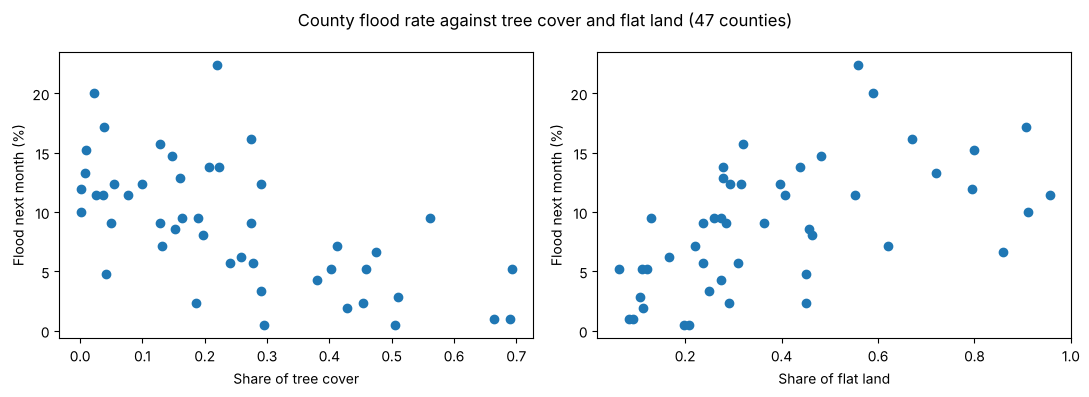

In [14]:
#flood rate against the two strongest static features
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(county['lc_tree'], county['flood_next_month'] * 100)
ax[0].set_xlabel('Share of tree cover')
ax[0].set_ylabel('Flood next month (%)')
ax[1].scatter(county['pct_flat'], county['flood_next_month'] * 100)
ax[1].set_xlabel('Share of flat land')
ax[1].set_ylabel('Flood next month (%)')
plt.suptitle('County flood rate against tree cover and flat land (47 counties)')
plt.tight_layout()
plt.show()

#### Observation

Both relations are clear but noisy. All 12 counties with more than 40% tree cover flood in less than 10% of months, and the 9 counties with more than 60% flat land flood in 6.7% to 17.1% of months. Kisumu (22.4%) is the highest point in both plots, with only average tree cover (22%) and flat land (56%), which shows that no single feature explains every county.

## 4. county_flood_rate

`county_flood_rate` is the share of flood months of each county in 2000 to 2019, which is the same period as the training rows. So on the training rows it has already seen the answers. To check how much this helps it unfairly, we make a fair version from July 2002 to December 2009 only, and test both versions on 2010 to 2019.

In [15]:
#splitting the training rows into an early and a late part
early = train[train['year_month'] <= 200912]
late = train[train['year_month'] >= 201001]

In [16]:
#fair version: flood rate of each county from the early part only
past_rate = early.groupby('pcode')['flood_this_month'].mean()
late_past_rate = late['pcode'].map(past_rate)

In [17]:
#auc on 2010-2019: the shipped county_flood_rate and the fair version
print(roc_auc_score(late['flood_next_month'], late['county_flood_rate']))
print(roc_auc_score(late['flood_next_month'], late_past_rate))

0.6716518685793674
0.6309456456013449


#### Observation

On 2010 to 2019, the shipped `county_flood_rate` has an AUC of 0.672, while the fair version made only from earlier years has 0.631. The shipped version is about 0.04 better because it has already seen the floods of the years it is tested on. The fair version is still a useful signal, so `county_flood_rate` can be kept, but in the models it must be recalculated from past months only inside each training fold.

## 5. Verdict for Each Feature

| feature | evidence | verdict | reason |
|---|---|---|---|
| `runoff_rank` | AUC 0.612, inside months 0.621 | keep | the strongest and most stable changing feature |
| `discharge_rank` | AUC 0.550, inside months 0.557 | keep | weaker, but the only river-flow feature |
| `discharge_rank_lag1` | AUC 0.513, inside months 0.509 | drop | almost no signal |
| `soil_moisture_l1` | AUC 0.477 raw, 0.612 as anomaly | keep (with care) | the raw value mixes place and weather |
| `soil_moisture_l2` and the two soil lags | AUC 0.390 to 0.453 raw | maybe drop | repeat `soil_moisture_l1` (checked in 04) |
| `lc_tree`, `pct_flat` | rho -0.64, +0.64 | keep | the two strongest static features |
| `pct_occasional_water`, `lc_grass`, `area_km2`, `pct_within_1km_river`, `lc_bare`, `pct_water` | rho +0.43 to +0.51 | keep | clear relation with the county flood rate |
| `elevation`, `slope` | rho -0.48, -0.46 | maybe drop | probably repeat `pct_flat` (checked in 04) |
| `pop_density`, `pct_built`, `lc_built` | rho -0.39, -0.41, -0.33 | keep one | describe the same thing (checked in 04) |
| `lc_crop`, `lc_shrub` | rho -0.35, +0.35 | `lc_crop` keep, `lc_shrub` maybe drop | weaker relations |
| `lc_water`, `pct_within_5km_river` | rho +0.43, +0.40 | maybe drop | probably repeat `pct_water` and `pct_within_1km_river` |
| `elev_std`, `lc_wetland`, `lc_mangrove`, `pct_within_1km_water` | p-value above 0.05 | drop | no clear relation |
| `county_flood_rate` | AUC 0.672 shipped, 0.631 fair | keep, only if recalculated | it has seen the training labels |

## 6. Summary

`runoff_rank` is the best changing feature and `discharge_rank` is weaker but useful. The raw soil moisture mostly tells us which county a row is from (dry counties flood often), and its weather signal only appears once the usual value of the county and month is removed (AUC 0.612). Most static features are related to the county flood rate, led by tree cover and flat land, but they rest on only 47 counties and many of them describe the same thing. `county_flood_rate` must be recalculated from past months inside every training fold. The next notebook, `04_feature_overlap_and_selection`, removes the features that repeat each other and writes the final list.